# 04b · Recommendation without Spark (`implicit` ALS)
Same data, split, evaluation (top-10, already-bought items removed, P/R/NDCG/HitRate@10) and nested user fractions as `04a`, but with the single-machine `implicit` library on a SciPy sparse matrix. The user subsets use the same rule as Spark (`pmod(xxhash64(user_id), 100) < p`), reproduced here via a user list exported from Spark.

Metrics go to `ml/outputs/04b_metrics.json`. Run `04a` first. Hyper-parameters are matched in spirit, not identically: Spark's `regParam` is scaled per user/item by rating count while `implicit` applies it plainly, so quality will not be bit-identical.

In [1]:
import os, json, time, resource, gc
import numpy as np, pandas as pd, scipy.sparse as sp
from IPython.display import display
import matplotlib.pyplot as plt
from implicit.als import AlternatingLeastSquares

DATA, OUT, FIG = "/home/jovyan/work/data", "/home/jovyan/work/ml/outputs", "/home/jovyan/work/laporan/gambar"
GOLD = f"{DATA}/gold"
SEED, RANK, MAXITER, ALPHA, REG, TOPN = 42, 32, 8, 10.0, 0.05, 10
# a user belongs to fraction p (percent) when pmod(hash(user_id), 100) < p; subsets are nested
FRACTIONS = [2, 10, 25, 100]

rss_gb = lambda: resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024 / 1024
spark_m = json.load(open(f"{OUT}/04a_metrics.json"))
metrics = dict(params=dict(rank=RANK, maxIter=MAXITER, alpha=ALPHA, regParam=REG, topN=TOPN), runs=[])

## Load and index
Raw ids become dense indices. Fraction membership comes from a small file of (user_id, bucket) written by Spark below, so both stacks use identical users.

In [2]:
# bucket = pmod(xxhash64(user_id), 100), computed with Spark in a throw-away session so the rule is literally identical
from pyspark.sql import SparkSession, functions as F
_sp = SparkSession.builder.master("local[2]").config("spark.driver.memory", "3g").getOrCreate()
buckets = (_sp.read.parquet(f"{GOLD}/als_train").select("user_id").distinct()
           .withColumn("bucket", F.pmod(F.xxhash64("user_id"), F.lit(100)).cast("int")).toPandas())
_sp.stop()
tr = pd.read_parquet(f"{GOLD}/als_train", columns=["user_id", "product_id", "n_purchase", "weight"]).merge(buckets, on="user_id")
te = pd.read_parquet(f"{GOLD}/als_test", columns=["user_id", "product_id"]).merge(buckets, on="user_id")
print(len(tr), len(te), f"peak RSS {rss_gb():.2f} GB")

50456607 113451 peak RSS 4.91 GB


In [3]:
def ndcg_at(rank_pos, n_rel):
    # rank_pos: 0-based positions of hits; ideal DCG over min(n_rel, TOPN)
    dcg = sum(1.0 / np.log2(r + 2) for r in rank_pos)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(min(n_rel, TOPN)))
    return dcg / idcg

def run(p):
    t = tr[tr.bucket < p]; e = te[te.bucket < p]
    uid = pd.Index(t.user_id.unique()); pid = pd.Index(t.product_id.unique())
    ui, pi = uid.get_indexer(t.user_id), pid.get_indexer(t.product_id)
    # confidence = alpha * weight (the library adds the +1 baseline internally)
    C = sp.csr_matrix((ALPHA * t.weight.to_numpy("float32"), (ui, pi)), shape=(len(uid), len(pid)))
    B = sp.csr_matrix((np.ones(int((t.n_purchase > 0).sum()), "float32"),
                       (ui[(t.n_purchase > 0).to_numpy()], pi[(t.n_purchase > 0).to_numpy()])), shape=C.shape)
    t0 = time.time()
    model = AlternatingLeastSquares(factors=RANK, regularization=REG, iterations=MAXITER, random_state=SEED,
                                    use_gpu=False, calculate_training_loss=False)
    model.fit(C, show_progress=False); fit_s = time.time() - t0
    t0 = time.time()
    e = e[e.user_id.isin(uid) & e.product_id.isin(pid)]
    rel = e.groupby("user_id").product_id.apply(set)
    users = uid.get_indexer(rel.index)
    ids, _ = model.recommend(users, B[users], N=TOPN, filter_already_liked_items=True)
    P, R, N_, H = [], [], [], []
    for row, (u, items) in enumerate(zip(rel.index, rel.values)):
        rec = pid[ids[row]]
        pos = [i for i, x in enumerate(rec) if x in items]
        P.append(len(pos) / TOPN); R.append(len(pos) / len(items)); N_.append(ndcg_at(pos, len(items))); H.append(float(len(pos) > 0))
    rec_s = time.time() - t0
    out = dict(fraction_pct=p, train_pairs=len(t), test_users=len(rel), fit_s=round(fit_s, 1), recommend_eval_s=round(rec_s, 1),
               peak_rss_gb=round(rss_gb(), 2),
               als=dict(users=len(rel), precision=float(np.mean(P)), recall=float(np.mean(R)), ndcg=float(np.mean(N_)), hit_rate=float(np.mean(H))))
    del model, C, B; gc.collect()
    return out

for p in FRACTIONS:
    try:
        r = run(p)
    except Exception as ex:
        r = dict(fraction_pct=p, error=str(ex)[:300])
    metrics["runs"].append(r); print(r)
    json.dump(metrics, open(f"{OUT}/04b_metrics.json", "w"), indent=2, default=str)

/opt/conda/lib/python3.11/site-packages/implicit/cpu/als.py:96: RuntimeWarning: OpenBLAS is configured to use 10 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


{'fraction_pct': 2, 'train_pairs': 1013419, 'test_users': 1598, 'fit_s': 4.7, 'recommend_eval_s': 0.2, 'peak_rss_gb': 4.91, 'als': {'users': 1598, 'precision': 0.02002503128911139, 'recall': 0.14563505434907187, 'ndcg': 0.08882438852709465, 'hit_rate': 0.18397997496871088}}


{'fraction_pct': 10, 'train_pairs': 5062861, 'test_users': 8007, 'fit_s': 15.0, 'recommend_eval_s': 1.1, 'peak_rss_gb': 4.91, 'als': {'users': 8007, 'precision': 0.019782690146122144, 'recall': 0.14592083831015895, 'ndcg': 0.0898486925028036, 'hit_rate': 0.18034220057449732}}


{'fraction_pct': 25, 'train_pairs': 12619596, 'test_users': 20068, 'fit_s': 32.9, 'recommend_eval_s': 2.7, 'peak_rss_gb': 4.91, 'als': {'users': 20068, 'precision': 0.01984253537970899, 'recall': 0.1492831443836466, 'ndcg': 0.09151391163669295, 'hit_rate': 0.18203109427944988}}


{'fraction_pct': 100, 'train_pairs': 50456607, 'test_users': 79571, 'fit_s': 126.5, 'recommend_eval_s': 11.2, 'peak_rss_gb': 6.1, 'als': {'users': 79571, 'precision': 0.019684307096806627, 'recall': 0.14814917402363512, 'ndcg': 0.0899799954917791, 'hit_rate': 0.1812343693054002}}


## Comparison with Spark MLlib

,fraction_pct,train_pairs,fit_s_spark,fit_s_implicit,ndcg_spark,ndcg_implicit,recall_spark,recall_implicit,ndcg_popularity,peak_rss_gb_implicit
0,2,1013419,7.6,4.7,0.0918,0.0888,0.1476,0.1456,0.0641,4.91
1,10,5062861,15.6,15.0,0.0907,0.0898,0.1478,0.1459,0.0642,4.91
2,25,12619596,32.0,32.9,0.0908,0.0915,0.1471,0.1493,0.0650,4.91
3,100,50456607,149.8,126.5,0.0893,0.0900,0.1465,0.1481,0.0644,6.10


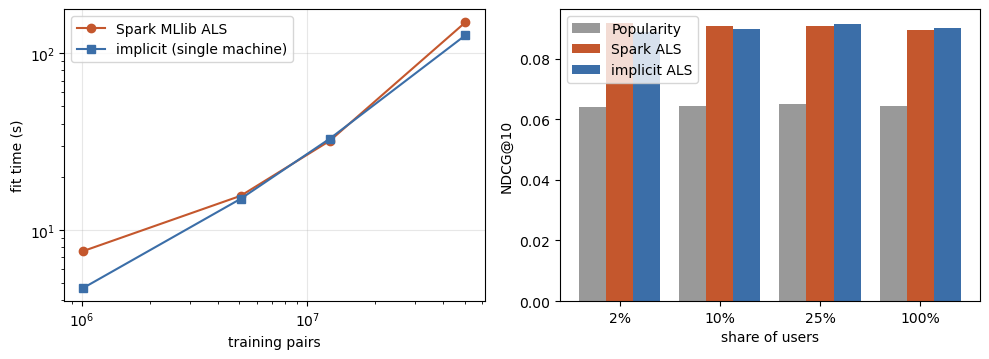

In [4]:
rows = []
sp_runs = {r["fraction_pct"]: r for r in spark_m["runs"] if "error" not in r}
for r in metrics["runs"]:
    if "error" in r: continue
    s = sp_runs.get(r["fraction_pct"])
    rows.append(dict(fraction_pct=r["fraction_pct"], train_pairs=r["train_pairs"],
        fit_s_spark=s and s["fit_s"], fit_s_implicit=r["fit_s"],
        ndcg_spark=s and s["als"]["ndcg"], ndcg_implicit=r["als"]["ndcg"],
        recall_spark=s and s["als"]["recall"], recall_implicit=r["als"]["recall"],
        ndcg_popularity=s and s["popularity"]["ndcg"], peak_rss_gb_implicit=r["peak_rss_gb"]))
cmp_ = pd.DataFrame(rows); display(cmp_.round(4))
metrics["comparison"] = cmp_.to_dict(orient="records")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.7))
ax[0].plot(cmp_.train_pairs, cmp_.fit_s_spark, "o-", color="#c4572d", label="Spark MLlib ALS")
ax[0].plot(cmp_.train_pairs, cmp_.fit_s_implicit, "s-", color="#3b6ea8", label="implicit (single machine)")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("training pairs"); ax[0].set_ylabel("fit time (s)"); ax[0].legend(); ax[0].grid(alpha=.3)
x = np.arange(len(cmp_)); w_ = 0.27
ax[1].bar(x - w_, cmp_.ndcg_popularity, w_, label="Popularity", color="#999999")
ax[1].bar(x, cmp_.ndcg_spark, w_, label="Spark ALS", color="#c4572d")
ax[1].bar(x + w_, cmp_.ndcg_implicit, w_, label="implicit ALS", color="#3b6ea8")
ax[1].set_xticks(x); ax[1].set_xticklabels([f"{p}%" for p in cmp_.fraction_pct]); ax[1].set_ylabel("NDCG@10"); ax[1].set_xlabel("share of users"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/fig_5_5_als_comparison.png", dpi=160); plt.show()
json.dump(metrics, open(f"{OUT}/04b_metrics.json", "w"), indent=2, default=str)